# Nuages de mots

## Imports et stopwords

In [43]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DERRICK\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [44]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
# Itération 1 (1960) : Les vocabulaire et les abréviations des petites annonces
sw += ["rue", "tél", "téléph", "app", "ecr", "écrire", "ecrire", "prés", "brux",
       "trav", "enf", "mod", "fem", "culs", "conf", "agence", "demande", "offre",
       "cherche", "présenter", "vente", "avenue", "mme", "bon", "bonne", "très",
       "prix", "vis", "soir"]
# Itération 2 (1960) : dates, durées et mots courants
sw += ["ans", "mois", "jours", "jour", "heures", "temps", "année", "matin", "midi",
       "lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche",
       "janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août",
       "septembre", "octobre", "novembre", "décembre", "avant", "peu", "toute",
       "quelques", "leurs", "vers", "devant", "déjà", "toujours", "etc", "chez",
       "celui", "alors", "fois", "également", "quatre", "plusieurs", "près", "lieu",
       "suite", "fin", "part", "partie", "place", "grand", "grande", "premier",
       "première", "dernier", "nouveau", "petit", "gros", "mal", "cours", "libre",
       "service"]
# Itération 3 (1960) : abréviations d'annonces encore présentes et mots vides restants
sw += ["réf", "mat", "rem", "gar", "bat", "bur", "bel", "mén", "pers", "louer",
       "dactylo", "bilingue", "firme", "dame", "importante", "ceux", "vue", "effet",
       "heure", "semaine", "demi", "neuf", "rien", "jamais", "ailleurs", "car",
       "point", "moment"]
sw = set(sw)


## Créer un fichier contenant le texte de tous les journaux d'une année donnée

In [45]:
# Choisir une année
year = 1960

In [46]:
# Lister les fichiers de cette année
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and f"_{year}-" in f]
len(txts)

100

In [47]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [48]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [49]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

"ia« le som ÏJsIne MéuhMrïiqii S.AT'BBirîï^^ J00, r. Merlu» Duché, Vllvorde ch. STENO-DACTYLO élément de let ordre, bilingue, bon- i ne rémunération. Situation d’avenir, i Candidat, A soumet par écrit "

In [50]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [51]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

'ia« le som ÏJsIne MéuhMrïiqii S.AT\'BBirîï^^ J00, r. Merlu» Duché, Vllvorde ch. STENO-DACTYLO élément de let ordre, bilingue, bon- i ne rémunération. Situation d’avenir, i Candidat, A soumet par écrit 130221H PORTANTE 80C.BRUXELL0I8I cherche pour entrée Immédiate Secrétaire Sténo-Dactylo 3 françalee - 1 an d\'expérience, al tuât h «table - semaine de 5 Jours. Ecrire é cur. vit et prêt Ag. Rossel 02983 H "âociËTS\'Importante de sa pi* demande 1 Sténo-Dactylo bilingue débutante. - Se présenter : 151.'

## Nettoyer le fichier à l'aide d'une fonction de nettoyage

### Créer la fonction de nettoyage (à adapter)

In [52]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    with open(output_path, "w", encoding='utf-8') as output:
        with open(input_path, 'r', encoding='utf-8') as f:
            text = f.read()
            words = nltk.wordpunct_tokenize(text)
            kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
            kept_string = " ".join(kept)
            output.write(kept_string)
    return f'Output has been written in {output_path}!'

### Appliquer la fonction sur le fichier complet de l'année

In [53]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1960_clean.txt!'

In [54]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'SOM ÏJSINE MÉUHMRÏIQII BBIRÎÏ MERLU DUCHÉ VLLVORDE STENO ÉLÉMENT LET ORDRE RÉMUNÉRATION SITUATION AVENIR CANDIDAT SOUMET ÉCRIT PORTANTE ENTRÉE IMMÉDIATE SECRÉTAIRE STÉNO FRANÇALEE EXPÉRIENCE TUÂT TABLE CUR VIT PRÊT ÂOCIËTS STÉNO DÉBUTANTE STALLE UCCLE CLE DELCO ASSURANCES INSPECTEUR PRODUCTEUR ACELDENTE INEENDLE VIE AGE RÉSIDENCE OBLIGATOIRE AJOST AUDENAERDE ENVIRONS APPOINTEMENTS RAIS ROUTE BARÈME RAIS VOITURE JURCOMNILSSLONS SITUATION STABLE AVENIR ÉLÉMENT DYNAMIQUE TRAVAILLEUR CURRICULUM VLTA'

## Nuage de mots

### Afficher les termes les plus fréquents


In [55]:
frequencies = Counter(after.split())
print(frequencies.most_common(50))

[('BRUXELLES', 1112), ('MAISON', 357), ('BELGIQUE', 346), ('BELGE', 333), ('CONGO', 294), ('FRANCS', 288), ('PAYS', 277), ('ANVERS', 270), ('JEUNE', 264), ('JEAN', 258), ('TRAVAIL', 251), ('SAINT', 247), ('ÉQUIPE', 223), ('MINISTRE', 217), ('SITUATION', 216), ('FRANCE', 215), ('ÉTAT', 212), ('BELGES', 210), ('CENTRE', 208), ('PARIS', 207), ('GÉNÉRAL', 195), ('TOUR', 194), ('FRANÇAIS', 193), ('HOMME', 193), ('GOUVERNEMENT', 191), ('ENFANTS', 187), ('DIVISION', 186), ('PRÉSIDENT', 186), ('LOUISE', 175), ('FEMME', 175), ('LOI', 175), ('ORDRE', 173), ('VIE', 173), ('BUREAU', 173), ('SOCIÉTÉ', 170), ('VOITURE', 169), ('LIÈGE', 169), ('HOMMES', 165), ('MARCHÉ', 164), ('CONSEIL', 162), ('MONDE', 162), ('CHAUSSÉE', 159), ('MILLIONS', 156), ('NAMUR', 155), ('NOUVELLE', 155), ('RAPPORT', 152), ('DÉBUT', 151), ('COUR', 150), ('NORD', 149), ('PIERRE', 146)]


### Créer, stocker et afficher le nuage de mots

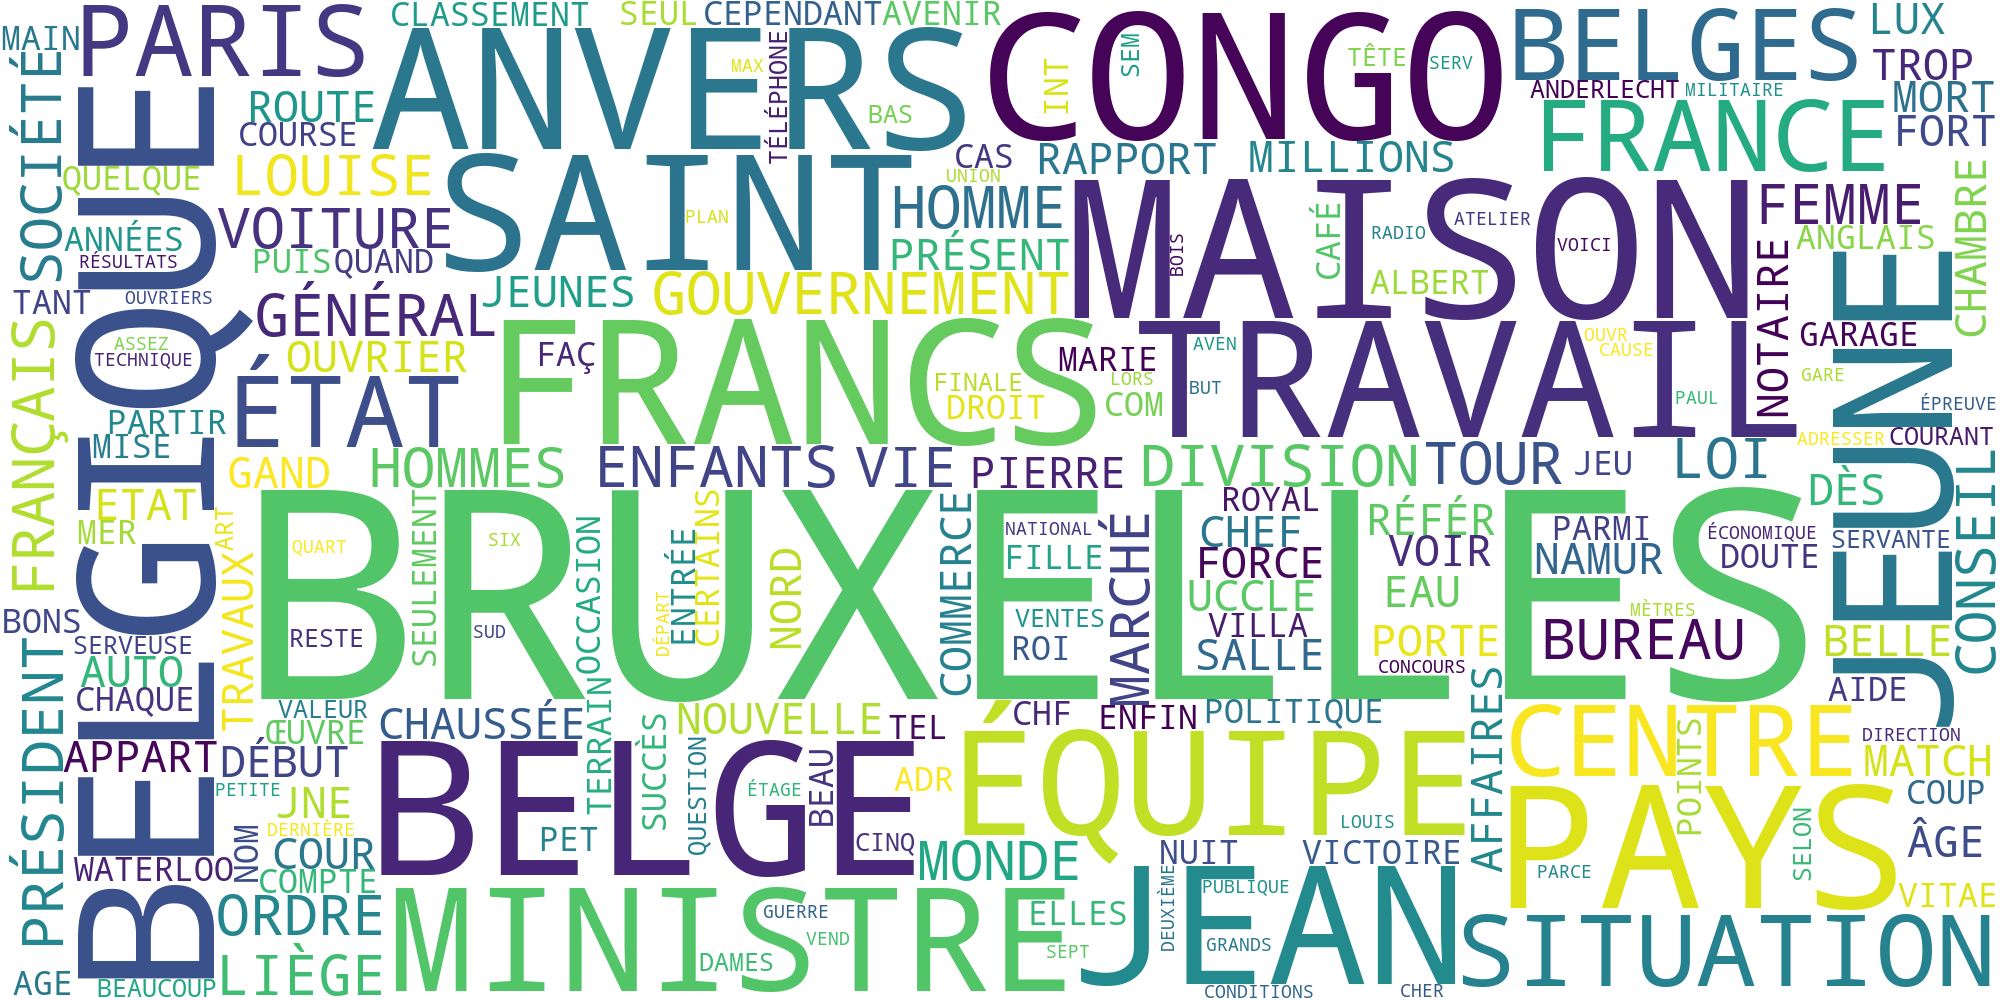

In [56]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(f"wordcloud_{year}.png")
Image(filename=f"wordcloud_{year}.png")